In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
from scipy.spatial import cKDTree
import uproot


df = pd.read_csv("cms_table4_ljets.csv")

df["value"] = df["value"] * 1000

data = uproot.concatenate({f: 'tree' for f in [
      'ntuples-mc/TTJets_TuneZ2_7TeV-madgraph-tauola/00000/ttbarSel_merged.root',
      'ntuples-mc/TTJets_TuneZ2_7TeV-madgraph-tauola/00001/ttbarSel_merged.root',
      'ntuples-mc/TTJets_TuneZ2_7TeV-madgraph-tauola/010000/ttbarSel_merged.root',
      'ntuples-mc/TTJets_TuneZ2_7TeV-madgraph-tauola/010001/ttbarSel_merged.root',
      'ntuples-mc/TTJets_TuneZ2_7TeV-madgraph-tauola/010002/ttbarSel_merged.root',
      'ntuples-mc/TTJets_TuneZ2_7TeV-madgraph-tauola/010003/ttbarSel_merged.root',
    ]}, ['mcEventType', 'mcT', 'mcTbar'], library='np')

data_t = data['mcT']
data_t_bar = data['mcTbar']
data_all = np.concatenate([data['mcT'], data['mcTbar']])

n = data_all.shape[0]
n1 = int(n/10)

data_all1 = data_all[:n1].copy()

data_a = np.hstack([data["mcT"], data["mcTbar"]])

n_a = data_a.shape[0]
n1_a = int(n_a/10)

data_a1 = data_a[:n1_a].copy()

def nn(x1, x2):
  # найближчий сусід
  tree = cKDTree(x1)
  _, i = tree.query(x2)
  # ваги
  weights = np.bincount(i, minlength=len(x1))
  sum_x2 = np.zeros_like(x1)
  np.add.at(sum_x2, i, x2)
  
  mask = weights > 0
  x1_corr = x1.copy()
  x1_corr[mask] = sum_x2[mask] / weights[mask, None]
  return x1, weights, x1_corr

_, weight, data_all1 = nn(data_all1, data_all)
_, weight, data_all1 = nn(data_all1, data_all)
_, weight, data_all1 = nn(data_all1, data_all)

_, weight_t, data_a1 = nn(data_a1, data_a)
_, weight_t, data_a1 = nn(data_a1, data_a)
_, weight_t, data_a1 = nn(data_a1, data_a)

data_t_comp = data_a1[:, :4]
data_t_bar_comp = data_a1[:, 4:]


RMS: 0.0017


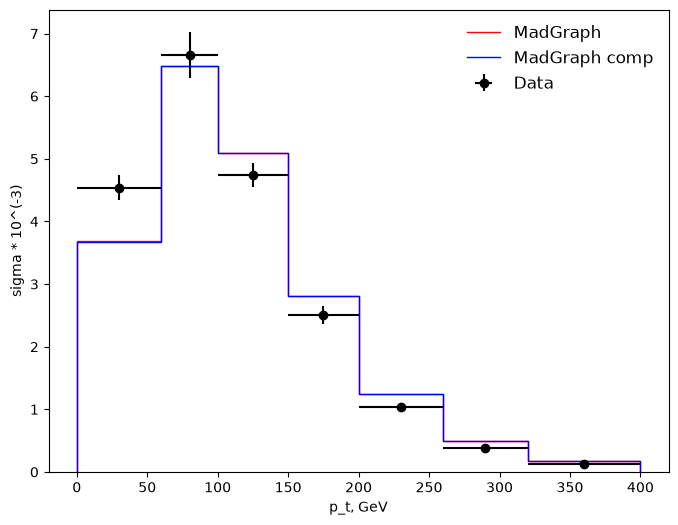

In [6]:
pt = df[df["observable"] == "pT_t"]

#print(pt)

x = (pt["bin_high"] + pt["bin_low"]) / 2
x_err = (pt["bin_high"] - pt["bin_low"]) / 2    

y = pt["value"]
y_total = pt["value"] * (pt["total"]/100)

#Згенеровані данні без стиснення 

data_pT_t = np.sqrt(data_all[:, 0]**2 + data_all[:, 1]**2)

bin = pt['bin_low']
bin = np.append(bin, 400)

bin_width = bin[1:] - bin[:-1]

count, _ = np.histogram(data_pT_t, bins=bin)
data_y = count / (len(data_pT_t) * bin_width)

#Згенеровані дані зі стисненням
data_pT_t_comp = np.sqrt(data_all1[:, 0]**2 + data_all1[:, 1]**2)

count_comp, _ = np.histogram(data_pT_t_comp, bins=bin, weights=weight)
data_y_comp = count_comp / (np.sum(weight) * bin_width)


#Побудова графіків
fig, ax = plt.subplots(figsize=(8, 6))

ax.set_xlabel("p_t, GeV")
ax.set_ylabel("sigma * 10^(-3)")

#Побудова точок зі статті
ax.errorbar(x, y, xerr=x_err, yerr=y_total, fmt='o', color='black', capsize=0, label='Data')

#Побудова MadGraph
ax.stairs(data_y * 1000, bin, color='red', label='MadGraph')

#Побудова стиснений MadGraph
ax.stairs(data_y_comp * 1000, bin, color='blue', label='MadGraph comp')


ax.legend(loc='upper right', frameon=False, fontsize=12)

mask = data_y > 0
rms = np.sqrt(np.mean((data_y_comp[mask] / data_y[mask] - 1)**2))
print(f"RMS: {rms:.4f}")

RMS: 0.0005


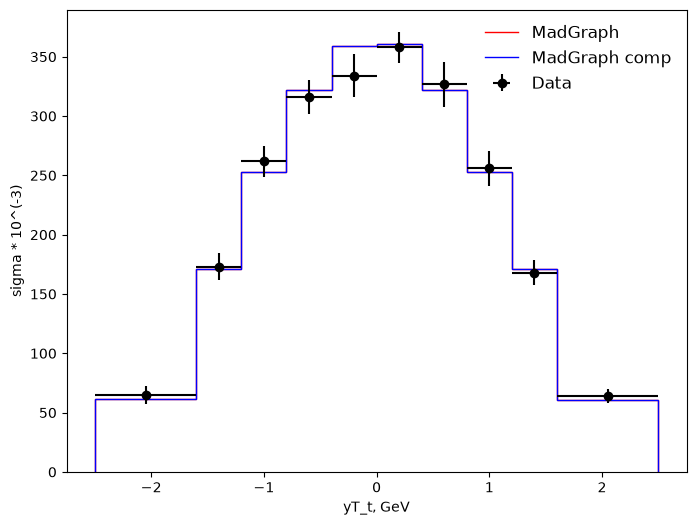

In [7]:
pt = df[df["observable"] == "y_t"]

#print(pt)

x = (pt["bin_high"] + pt["bin_low"]) / 2
x_err = (pt["bin_high"] - pt["bin_low"]) / 2    

y = pt["value"]
y_total = pt["value"] * (pt["total"] / 100)

#Згенеровані данні без стиснення 

def rapidity(p):
    E = np.sqrt(p[:, 0]**2 + p[:, 1]**2 + p[:, 2]**2 + p[:, 3]**2 )
    return 0.5*np.log((E + p[:, 2]) / ((E - p[:, 2])))

data_pT_t = rapidity(data_all)

bin = pt['bin_low']
bin = np.append(bin, pt['bin_high'].iloc[-1])

bin_width = bin[1:] - bin[:-1]

count, _ = np.histogram(data_pT_t, bins=bin)
data_y = count / (len(data_pT_t) * bin_width)

#Згенеровані дані зі стисненням
data_pT_t_comp = rapidity(data_all1)

count_comp, _ = np.histogram(data_pT_t_comp, bins=bin, weights=weight)
data_y_comp = count_comp / (np.sum(weight) * bin_width)


#Побудова графіків
fig, ax = plt.subplots(figsize=(8, 6))

ax.set_xlabel("yT_t, GeV")
ax.set_ylabel("sigma * 10^(-3)")

#Побудова точок зі статті
ax.errorbar(x, y, xerr=x_err, yerr=y_total, fmt='o', color='black', capsize=0, label='Data')

#Побудова MadGraph
ax.stairs(data_y * 1000, bin, color='red', label='MadGraph')

#Побудова стиснений MadGraph
ax.stairs(data_y_comp * 1000, bin, color='blue', label='MadGraph comp')


ax.legend(loc='upper right', frameon=False, fontsize=12)

mask = data_y > 0
rms = np.sqrt(np.mean((data_y_comp[mask] / data_y[mask] - 1)**2))
print(f"RMS: {rms:.4f}")

RMS: 0.2084


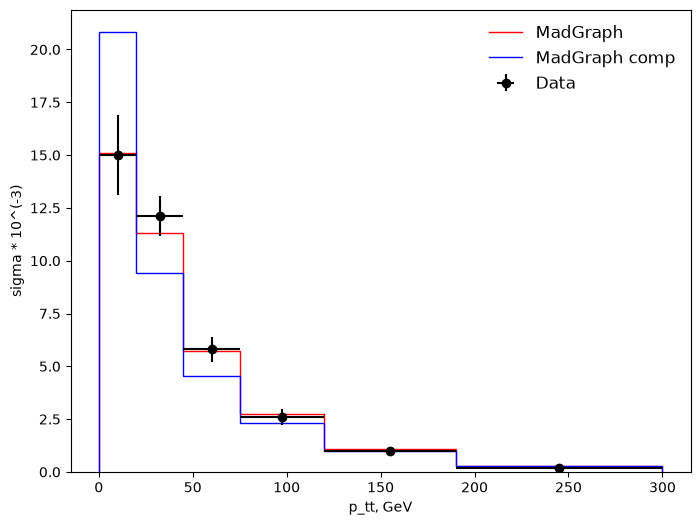

In [8]:
pt = df[df["observable"] == "pT_tt"]

#print(pt)

x = (pt["bin_high"] + pt["bin_low"]) / 2
x_err = (pt["bin_high"] - pt["bin_low"]) / 2    

y = pt["value"]
y_total = pt["value"] * (pt["total"]/100)

#Згенеровані данні без стиснення 

data_pT_t = np.sqrt((data_t[:, 0] + data_t_bar[:, 0])**2 + (data_t[:, 1] + data_t_bar[:, 1])**2)

bin = pt['bin_low']
bin = np.append(bin, pt['bin_high'].iloc[-1])

bin_width = bin[1:] - bin[:-1]

count, _ = np.histogram(data_pT_t, bins=bin)
data_y = count / (len(data_pT_t) * bin_width)

#Згенеровані дані зі стисненням
data_pT_t_comp = np.sqrt((data_t_comp[:, 0] + data_t_bar_comp[:, 0])**2 + (data_t_comp[:, 1] + data_t_bar_comp[:, 1])**2)

count_comp, _ = np.histogram(data_pT_t_comp, bins=bin, weights=weight_t)
data_y_comp = count_comp / (np.sum(weight_t) * bin_width)


#Побудова графіків
fig, ax = plt.subplots(figsize=(8, 6))

ax.set_xlabel("p_tt, GeV")
ax.set_ylabel("sigma * 10^(-3)")

#Побудова точок зі статті
ax.errorbar(x, y, xerr=x_err, yerr=y_total, fmt='o', color='black', capsize=0, label='Data')

#Побудова MadGraph
ax.stairs(data_y * 1000, bin, color='red', label='MadGraph')

#Побудова стиснений MadGraph
ax.stairs(data_y_comp * 1000, bin, color='blue', label='MadGraph comp')


ax.legend(loc='upper right', frameon=False, fontsize=12)

mask = data_y > 0
rms = np.sqrt(np.mean((data_y_comp[mask] / data_y[mask] - 1)**2))
print(f"RMS: {rms:.4f}")

RMS: 0.0037


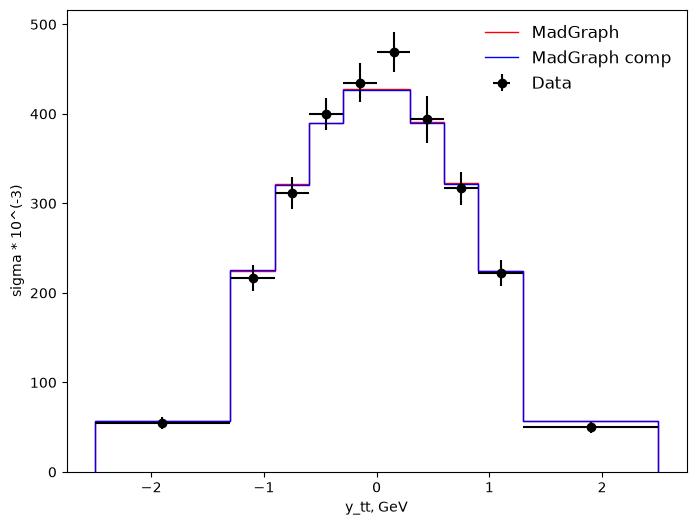

In [9]:
pt = df[df["observable"] == "y_tt"]

#print(pt)

x = (pt["bin_high"] + pt["bin_low"]) / 2
x_err = (pt["bin_high"] - pt["bin_low"]) / 2    

y = pt["value"]
y_total = pt["value"] * (pt["total"] / 100)

#Згенеровані данні без стиснення 

def rapidity(p, p_bar):
    E_t = np.sqrt(p[:, 0]**2 + p[:, 1]**2 + p[:, 2]**2 + p[:, 3]**2)
    E_t_bar = np.sqrt(p_bar[:, 0]**2 + p_bar[:, 1]**2 + p_bar[:, 2]**2 + p_bar[:, 3]**2)
    return 0.5*np.log((E_t + E_t_bar + p[:, 2] + p_bar[:, 2]) / (E_t + E_t_bar - p[:, 2]- p_bar[:, 2]))

data_pT_t = rapidity(data_t, data_t_bar)

bin = pt['bin_low']
bin = np.append(bin, pt['bin_high'].iloc[-1])

bin_width = bin[1:] - bin[:-1]

count, _ = np.histogram(data_pT_t, bins=bin)
data_y = count / (len(data_pT_t) * bin_width)

#Згенеровані дані зі стисненням
data_pT_t_comp = rapidity(data_t_comp, data_t_bar_comp)

count_comp, _ = np.histogram(data_pT_t_comp, bins=bin, weights=weight_t)
data_y_comp = count_comp / (np.sum(weight_t) * bin_width)


#Побудова графіків
fig, ax = plt.subplots(figsize=(8, 6))

ax.set_xlabel("y_tt, GeV")
ax.set_ylabel("sigma * 10^(-3)")

#Побудова точок зі статті
ax.errorbar(x, y, xerr=x_err, yerr=y_total, fmt='o', color='black', capsize=0, label='Data')

#Побудова MadGraph
ax.stairs(data_y * 1000, bin, color='red', label='MadGraph')

#Побудова стиснений MadGraph
ax.stairs(data_y_comp * 1000, bin, color='blue', label='MadGraph comp')


ax.legend(loc='upper right', frameon=False, fontsize=12)

mask = data_y > 0
rms = np.sqrt(np.mean((data_y_comp[mask] / data_y[mask] - 1)**2))
print(f"RMS: {rms:.4f}")

RMS: 0.0324


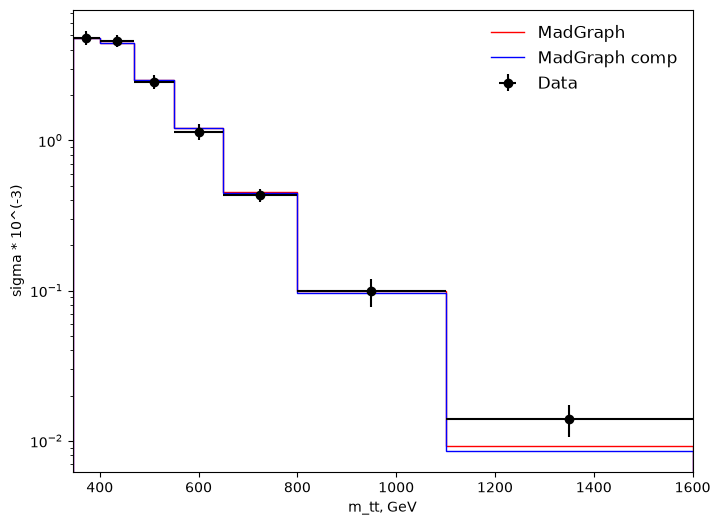

In [10]:
pt = df[df["observable"] == "m_tt"]

#print(pt)

x = (pt["bin_high"] + pt["bin_low"]) / 2
x_err = (pt["bin_high"] - pt["bin_low"]) / 2    

y = pt["value"]
y_total = pt["value"] * (pt["total"] / 100)

#Згенеровані данні без стиснення 

def mass(p, p_bar):
    E_t = np.sqrt(p[:, 0]**2 + p[:, 1]**2 + p[:, 2]**2 + p[:, 3]**2)
    E_t_bar = np.sqrt(p_bar[:, 0]**2 + p_bar[:, 1]**2 + p_bar[:, 2]**2 + p_bar[:, 3]**2)

    p_tt = ((p[:, 0] + p_bar[:, 0])**2 + (p[:, 1] + p_bar[:, 1])**2 + (p[:, 2] + p_bar[:, 2])**2)


    return np.sqrt((E_t + E_t_bar)**2 - p_tt)

data_pT_t = mass(data_t, data_t_bar)

bin = pt['bin_low']
bin = np.append(bin, pt['bin_high'].iloc[-1])

bin_width = bin[1:] - bin[:-1]

count, _ = np.histogram(data_pT_t, bins=bin)
data_y = count / (len(data_pT_t) * bin_width)

#Згенеровані дані зі стисненням
data_pT_t_comp = mass(data_t_comp, data_t_bar_comp)

count_comp, _ = np.histogram(data_pT_t_comp, bins=bin, weights=weight_t)
data_y_comp = count_comp / (np.sum(weight_t) * bin_width)


#Побудова графіків
fig, ax = plt.subplots(figsize=(8, 6))

ax.set_xlabel("m_tt, GeV")
ax.set_ylabel("sigma * 10^(-3)")

ax.set_yscale('log')

ax.set_xlim(345, 1600)

#Побудова точок зі статті
ax.errorbar(x, y, xerr=x_err, yerr=y_total, fmt='o', color='black', capsize=0, label='Data')

#Побудова MadGraph
ax.stairs(data_y * 1000, bin, color='red', label='MadGraph')

#Побудова стиснений MadGraph
ax.stairs(data_y_comp * 1000, bin, color='blue', label='MadGraph comp')


ax.legend(loc='upper right', frameon=False, fontsize=12)

mask = data_y > 0
rms = np.sqrt(np.mean((data_y_comp[mask] / data_y[mask] - 1)**2))
print(f"RMS: {rms:.4f}")